# 01 · Deutsch–Jozsa

Run: [setup](../SETUP.md). Qiskit ideal simulation; saved outputs are local. Run your version in qBraid Lab (or implement it in Classiq).

**Question:** is a yes/no rule constant or balanced? **Input:** a function mapping three bits to one bit, promised to return either the same value for all eight inputs or 1 for exactly four. **Output:** that classification, not every function value. Useful as a first example of learning a property without listing every answer. It is a teaching problem: ordinary firmware rarely satisfies the promise.

1. Apply **H (Hadamard)** gates to give inputs equal amplitudes: signed weights whose squared magnitudes are probabilities. Prepare a helper qubit with equal but opposite-signed amplitudes.
2. Call an **oracle**, a reversible circuit implementing the function. It flips the helper when the function returns 1, changing that input amplitude's sign.
3. Apply H again. **Interference** combines amplitudes: balanced signs cancel the all-zero outcome; constant signs reinforce it. Measure only the input qubits.

In [1]:
%matplotlib inline
import qiskit
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

print('Qiskit', qiskit.__version__)
N, SHOTS, SEED = 3, 512, 2026

def deutsch_jozsa(case):
    assert case in {'constant', 'balanced', 'one_defect'}
    circuit = QuantumCircuit(N + 1)
    circuit.x(N)                      # X then H prepares the helper
    circuit.h(range(N + 1))
    # Oracle: constant zero, XOR of bits 0 and 2, or only input 111.
    if case == 'balanced':
        circuit.cx(0, N)               # controlled-X flips the helper
        circuit.cx(2, N)
    elif case == 'one_defect':
        circuit.mcx(list(range(N)), N)  # flip only if every input is 1
    circuit.h(range(N))
    return circuit

Qiskit 2.3.0


**Predict:** which case returns `000`? Our balanced function is `bit_2 XOR bit_0`. Qiskit prints bits as `q2 q1 q0`, with qubit 0 on the right. Each shot below samples one simulated measurement.

constant: most common result 000 | classical check passed
balanced: most common result 101 | classical check passed


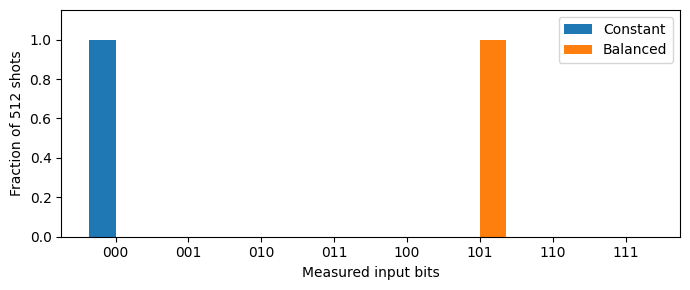

One defect: P(000) = 0.5625, despite a nonconstant function.


In [2]:
# Ordinary Python truth tables provide an independent reference.
tables = {
    'constant': [0] * 8,
    'balanced': [((x >> 2) & 1) ^ (x & 1) for x in range(8)],
}
labels = [format(x, '03b') for x in range(8)]
frequencies = {}
for case, table in tables.items():
    state = Statevector.from_instruction(deutsch_jozsa(case))
    state.seed(SEED)
    probabilities = state.probabilities(qargs=list(range(N)))
    counts = state.sample_counts(SHOTS, qargs=list(range(N)))
    is_constant = len(set(table)) == 1
    assert np.isclose(probabilities[0], int(is_constant))
    frequencies[case] = [counts.get(label, 0) / SHOTS for label in labels]
    print(f"{case}: most common result {max(counts, key=counts.get)} | classical check passed")

x = np.arange(8)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(x - .18, frequencies['constant'], .36, label='Constant')
ax.bar(x + .18, frequencies['balanced'], .36, label='Balanced')
ax.set(xticks=x, xticklabels=labels, xlabel='Measured input bits',
       ylabel=f'Fraction of {SHOTS} shots', ylim=(0, 1.15))
ax.legend()
plt.tight_layout()
plt.show()

# Violate the promise: just one input returns 1. Zero no longer means constant.
defect = Statevector.from_instruction(deutsch_jozsa('one_defect'))
p_zero = defect.probabilities(qargs=list(range(N)))[0]
assert np.isclose(p_zero, (6 / 8)**2)
print(f'One defect: P(000) = {p_zero:.4f}, despite a nonconstant function.')

Under the promise, `000` means constant; any other string means balanced. With $n$ input bits, the ideal algorithm uses one oracle query, versus $2^{n-1}+1$ worst-case deterministic classical queries. Randomized classical sampling needs only a few queries for high confidence. Oracle construction and gates also cost resources; repeated shots repeat the query. This simulator run demonstrates no runtime advantage.

**Try:** change the balanced oracle to depend only on bit 1, update its classical truth table, and predict the measured string.

[IBM algorithm explanation](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/quantum-query-algorithms/deutsch-jozsa-algorithm).